# Smart Supply Chain Performance & Delivery Risk Analytics

## Notebook Python (Google Colab). Sumber data: tabel `supply_chain_final` di BigQuery
## (project `supply-chain-513612`, dataset `SupplyChain`), periode 2015-2017.

### 1. Hubungkan ke BigQuery

In [ ]:
from google.colab import auth
auth.authenticate_user()

### 2. Tarik data dari `supply_chain_final`

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ID = "supply-chain-513612"

query = """
SELECT *
FROM `supply-chain-513612.SupplyChain.supply_chain_final`
"""

df = pd.read_gbq(query, project_id=PROJECT_ID)
print(df.shape)
df.head()

/tmp/ipykernel_469/741534720.py:14: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  df = pd.read_gbq(query, project_id=PROJECT_ID)


(178396, 23)


,order_id,order_item_id,order_date,shipping_date,days_for_shipping_real,days_for_shipment_scheduled,delivery_status,late_delivery_risk,shipping_mode,market,...,sales,benefit_per_order,order_item_quantity,category_name,department_name,delay_gap,is_late,order_year,order_month,profit_margin
0,1,1,2015-01-01 00:00:00+00:00,2015-01-03 00:00:00+00:00,2,4,Advance shipping,0,Standard Class,LATAM,...,299.980011,88.790001,1,Camping & Hiking,Fan Shop,-2,0,2015,1,0.295986
1,11,33,2015-01-01 03:30:00+00:00,2015-01-03 03:30:00+00:00,2,4,Advance shipping,0,Standard Class,LATAM,...,249.899994,62.540001,5,Indoor/Outdoor Games,Fan Shop,-2,0,2015,1,0.250260
2,11,30,2015-01-01 03:30:00+00:00,2015-01-03 03:30:00+00:00,2,4,Advance shipping,0,Standard Class,LATAM,...,159.960007,56.990002,4,Shop By Sport,Golf,-2,0,2015,1,0.356277
3,11,31,2015-01-01 03:30:00+00:00,2015-01-03 03:30:00+00:00,2,4,Advance shipping,0,Standard Class,LATAM,...,49.980000,19.500000,1,Indoor/Outdoor Games,Fan Shop,-2,0,2015,1,0.390156
4,11,32,2015-01-01 03:30:00+00:00,2015-01-03 03:30:00+00:00,2,4,Advance shipping,0,Standard Class,LATAM,...,399.959992,117.169998,4,Cardio Equipment,Footwear,-2,0,2015,1,0.292954


### 3. Cek data

In [ ]:
df.info()

print(df.isna().sum())
print("Duplikat:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 23 columns):
 #   Column                       Non-Null Count   Dtype              
---  ------                       --------------   -----              
 0   order_id                     178396 non-null  Int64              
 1   order_item_id                178396 non-null  Int64              
 2   order_date                   178396 non-null  datetime64[us, UTC]
 3   shipping_date                178396 non-null  datetime64[us, UTC]
 4   days_for_shipping_real       178396 non-null  Int64              
 5   days_for_shipment_scheduled  178396 non-null  Int64              
 6   delivery_status              178396 non-null  object             
 7   late_delivery_risk           178396 non-null  Int64              
 8   shipping_mode                178396 non-null  object             
 9   market                       178396 non-null  object             
 10  order_region                 178

### 4. Cross-check KPI dengan SQL (tanpa pesanan batal)

In [ ]:
# keluarkan pesanan batal
df_valid = df[df["delivery_status"] != "Shipping canceled"].copy()

kpi = {
    "total_orders": df_valid["order_id"].nunique(),
    "total_units": df_valid["order_item_quantity"].sum(),
    "total_sales": round(df_valid["sales"].sum(), 2),
    "total_profit": round(df_valid["benefit_per_order"].sum(), 2),
    "profit_margin_pct": round(100 * df_valid["benefit_per_order"].sum() / df_valid["sales"].sum(), 2),
    "late_rate_pct": round(100 * df_valid["is_late"].mean(), 2),
    "avg_shipping_days": round(df_valid["days_for_shipping_real"].mean(), 2),
    "avg_delay_gap": round(df_valid["delay_gap"].mean(), 2),
}
pd.Series(kpi)

,0
total_orders,60860.00
total_units,365554.00
total_sales,34897716.93
total_profit,3774057.03
profit_margin_pct,10.81
late_rate_pct,57.27
avg_shipping_days,3.50
avg_delay_gap,0.56


### 5. Analisis shipping mode dan keterlambatan

#### 5.1 Late rate per shipping mode

In [ ]:
mode = df_valid.groupby("shipping_mode").agg(
    total_items=("is_late", "size"),
    late_rate_pct=("is_late", lambda x: round(100 * x.mean(), 2)),
    avg_scheduled=("days_for_shipment_scheduled", "mean"),
    avg_real=("days_for_shipping_real", "mean"),
    avg_delay_gap=("delay_gap", "mean"),
).round(2).sort_values("late_rate_pct", ascending=False)
mode

,total_items,late_rate_pct,avg_scheduled,avg_real,avg_delay_gap
shipping_mode,,,,,
First Class,26192,100.00,1.0,2.0,1.0
Second Class,33381,79.82,2.0,3.99,1.99
Same Day,9181,47.97,0.0,0.48,0.48
Standard Class,101974,39.76,4.0,3.99,-0.01


#### 5.2 Grafik late rate per mode

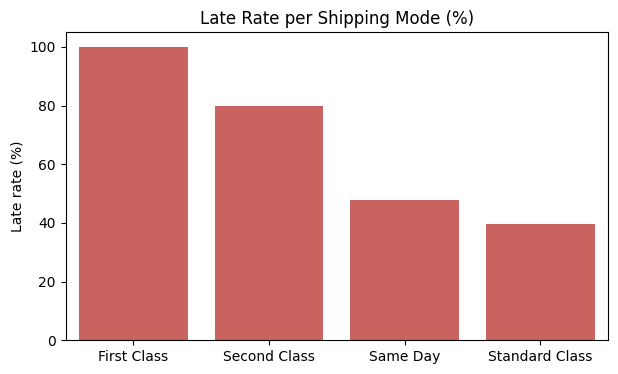

In [ ]:
plt.figure(figsize=(7, 4))
sns.barplot(data=mode.reset_index(), x="shipping_mode", y="late_rate_pct", color="#d9534f")
plt.title("Late Rate per Shipping Mode (%)")
plt.xlabel("")
plt.ylabel("Late rate (%)")
plt.show()

#### 5.3 Sebaran selisih hari per mode

In [ ]:
print(pd.crosstab(df_valid["shipping_mode"], df_valid["delay_gap"]))

delay_gap          -2     -1     0      1      2     3     4 
shipping_mode                                                
First Class         0      0      0  26192      0     0     0
Same Day            0      0   4777   4404      0     0     0
Second Class        0      0   6737   6676   6667  6683  6618
Standard Class  20636  20488  20308  19999  20543     0     0


#### 5.4 Profit: terlambat vs tidak

In [ ]:
df_valid.groupby("is_late")[["sales", "benefit_per_order", "profit_margin"]].mean().round(3)

,sales,benefit_per_order,profit_margin
is_late,,,
0,205.112,22.694,0.110
1,203.878,21.667,0.107


#### 5.5 Konsistensi `late_delivery_risk` dengan `delivery_status`

In [ ]:
pd.crosstab(df["delivery_status"], df["late_delivery_risk"])

late_delivery_risk,0,1
delivery_status,,
Advance shipping,41124,0
Late delivery,0,97782
Shipping canceled,7668,0
Shipping on time,31822,0


#### 5.6 Status pengiriman vs selisih hari

In [ ]:
pd.crosstab(df_valid["delivery_status"], df_valid["delay_gap"])

delay_gap,-2,-1,0,1,2,3,4
delivery_status,,,,,,,
Advance shipping,20636,20488,0,0,0,0,0
Late delivery,0,0,0,57271,27210,6683,6618
Shipping on time,0,0,31822,0,0,0,0


### 6. Analisis market, region, waktu, dan kategori


#### 6.1 Late rate per market


In [ ]:
market = df_valid.groupby("market").agg(
    total_orders=("order_id", "nunique"),
    total_sales=("sales", "sum"),
    total_profit=("benefit_per_order", "sum"),
    late_rate_pct=("is_late", lambda x: 100 * x.mean()),
).round(2).sort_values("total_sales", ascending=False)
market

,total_orders,total_sales,total_profit,late_rate_pct
market,,,,
Europe,17763,10405371.44,1131937.91,57.69
LATAM,16414,9824329.76,1069050.79,56.87
Pacific Asia,14816,7625639.10,793803.56,57.31
USCA,8178,4836413.58,539223.29,57.41
Africa,3689,2205963.05,240041.48,56.84


#### 6.2 Late rate per region

In [ ]:
region = df_valid.groupby("order_region").agg(
    total_items=("is_late", "size"),
    late_rate_pct=("is_late", lambda x: 100 * x.mean()),
).round(2).sort_values("late_rate_pct", ascending=False)
region

,total_items,late_rate_pct
order_region,,
Central Africa,1616,60.15
Western Europe,25867,58.53
South of USA,3855,58.52
South Asia,7000,58.50
East Africa,1781,58.17
East of USA,6617,58.17
Southeast Asia,8508,57.97
West Asia,5746,57.81
Eastern Europe,3785,57.65


#### 6.3 Heatmap shipping mode x market

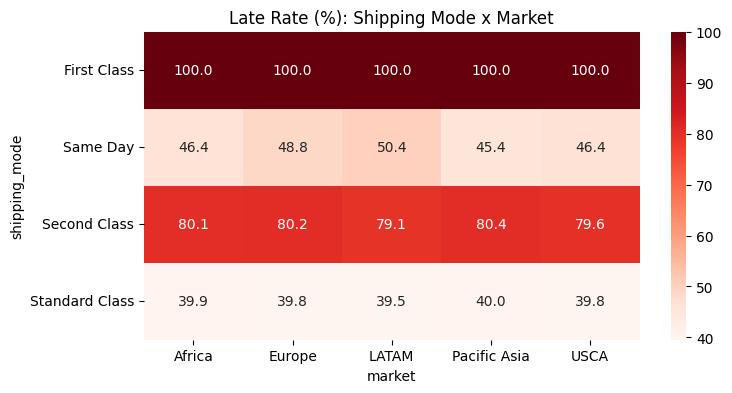

In [ ]:
### Heatmap Shipping Mode x Market
pivot = df_valid.pivot_table(index="shipping_mode", columns="market",
                             values="is_late", aggfunc="mean") * 100
# Konversi tipe data pivot ke float agar bisa digambar oleh seaborn
pivot = pivot.astype(float)

plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Late Rate (%): Shipping Mode x Market")
plt.show()

#### 6.4 Tren bulanan


/tmp/ipykernel_469/1064730154.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_valid["year_month"] = df_valid["order_date"].dt.to_period("M").astype(str)


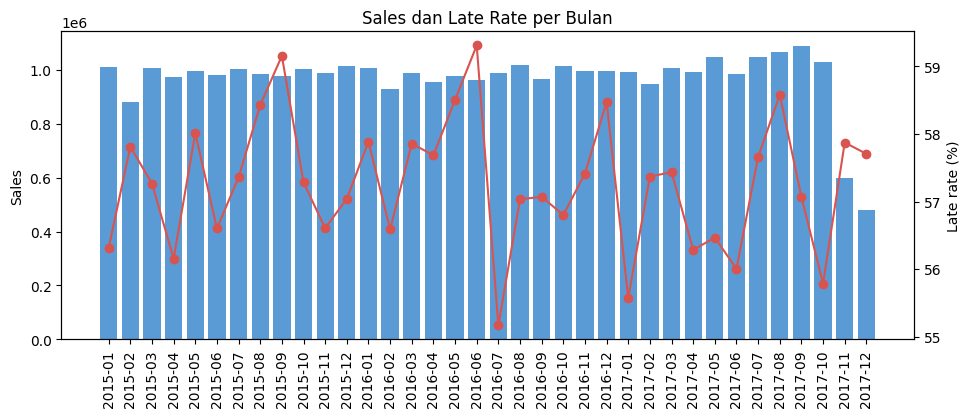

In [ ]:
df_valid["year_month"] = df_valid["order_date"].dt.to_period("M").astype(str)
monthly = df_valid.groupby("year_month").agg(
    sales=("sales", "sum"),
    profit=("benefit_per_order", "sum"),
    late_rate=("is_late", lambda x: 100 * x.mean()),
).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly["year_month"], monthly["sales"], color="#5b9bd5")
ax1.set_ylabel("Sales")
ax1.tick_params(axis="x", rotation=90)
ax2 = ax1.twinx()
ax2.plot(monthly["year_month"], monthly["late_rate"], color="#d9534f", marker="o")
ax2.set_ylabel("Late rate (%)")
plt.title("Sales dan Late Rate per Bulan")
plt.show()

#### 6.5 Top 10 Kategori Produk

In [ ]:
cat = df_valid.groupby("category_name").agg(
    total_sales=("sales", "sum"),
    total_profit=("benefit_per_order", "sum"),
    late_rate_pct=("is_late", lambda x: 100 * x.mean()),
).round(2).sort_values("total_sales", ascending=False).head(10)
cat

,total_sales,total_profit,late_rate_pct
category_name,,,
Fishing,6637668.28,731576.19,57.34
Cleats,4244594.01,474629.51,57.40
Camping & Hiking,3946837.00,409895.62,56.91
Cardio Equipment,3533289.21,362984.70,56.96
Women's Apparel,3011600.00,334335.53,57.05
Water Sports,2981851.28,308981.34,57.24
Indoor/Outdoor Games,2765543.31,302403.77,57.20
Men's Footwear,2763977.49,296711.09,57.01
Shop By Sport,1253395.63,125077.03,57.61


#### 6.6 Item per order per tahun

In [ ]:
items = df_valid.groupby("order_year").agg(
    items=("order_item_id", "count"),
    orders=("order_id", "nunique"),
)
items["item_per_order"] = (items["items"] / items["orders"]).round(2)
items

,items,orders,item_per_order
order_year,,,
2015,59954,19995,3.0
2016,59926,19955,3.0
2017,50848,20910,2.43


### 7. Analisis lanjutan


#### 7.1 Item per order per bulan (temuan: pola berubah sejak Okt 2017)

In [ ]:
m = df_valid.groupby("year_month").agg(
    items=("order_item_id", "count"),
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
)
m["item_per_order"] = (m["items"] / m["orders"]).round(2)
m.tail(12)

,items,orders,sales,item_per_order
year_month,,,,
2017-01,5033,1685,9.924190e+05,2.99
2017-02,4675,1538,9.480418e+05,3.04
2017-03,5145,1710,1.007894e+06,3.01
2017-04,4980,1666,9.915332e+05,2.99
2017-05,5035,1672,1.047041e+06,3.01
2017-06,4730,1605,9.857683e+05,2.95
2017-07,5052,1693,1.047375e+06,2.98
2017-08,5111,1695,1.067685e+06,3.02
2017-09,4931,1640,1.088272e+06,3.01


#### 7.2 Profit per shipping mode

In [ ]:
df_valid.groupby("shipping_mode").agg(
    total_sales=("sales", "sum"),
    total_profit=("benefit_per_order", "sum"),
    avg_margin=("profit_margin", "mean"),
).round(3)

,total_sales,total_profit,avg_margin
shipping_mode,,,
First Class,5.353364e+06,611380.351,0.114
Same Day,1.837990e+06,190886.400,0.105
Second Class,6.794838e+06,716332.120,0.106
Standard Class,2.091153e+07,2255458.163,0.108


#### 7.3 Departemen

In [ ]:
df_valid.groupby("department_name").agg(
    total_sales=("sales", "sum"),
    late_rate_pct=("is_late", lambda x: 100 * x.mean()),
).round(2).sort_values("total_sales", ascending=False)

,total_sales,late_rate_pct
department_name,,
Fan Shop,16389360.33,57.21
Apparel,7546790.13,57.20
Golf,4407982.24,57.28
Footwear,3833832.17,57.22
Outdoors,1151940.55,57.95
Technology,994974.41,57.74
Fitness,314937.47,57.56
Discs Shop,159437.83,55.88
Health and Beauty,66813.12,58.33


#### 7.4 Top 10 negara berdasarkan sales

In [ ]:
df_valid.groupby("order_country").agg(
    total_orders=("order_id", "nunique"),
    total_sales=("sales", "sum"),
    late_rate_pct=("is_late", lambda x: 100 * x.mean()),
).round(2).sort_values("total_sales", ascending=False).head(10)

,total_orders,total_sales,late_rate_pct
order_country,,,
Estados Unidos,7887,4659618.21,57.63
Francia,4648,2753970.85,58.21
México,4201,2522997.51,57.49
Alemania,3368,1986194.39,58.80
Reino Unido,2661,1544403.72,55.82
Australia,3119,1541924.63,56.49
Brasil,2520,1513085.23,57.14
China,2152,1071551.12,56.52
Italia,1793,1021387.17,56.10


#### 7.5 Kategori keterlambatan

In [ ]:
df_valid["delay_category"] = pd.cut(
    df_valid["delay_gap"],
    bins=[-10, -1, 0, 2, 100],
    labels=["Lebih cepat", "Tepat waktu", "Terlambat 1-2 hari", "Terlambat 3-4 hari"],
)
df_valid["delay_category"].value_counts()

,count
delay_category,
Terlambat 1-2 hari,84481
Lebih cepat,41124
Tepat waktu,31822
Terlambat 3-4 hari,13301


## EKSPOR DATA KE POWER BI

In [ ]:
from google.colab import files

# buang info zona waktu supaya Power BI membaca tanggal dengan benar
df_valid["order_date"] = df_valid["order_date"].dt.tz_localize(None)
df_valid["shipping_date"] = df_valid["shipping_date"].dt.tz_localize(None)

# penanda periode dengan pola data berbeda
df_valid["order_period_flag"] = np.where(
    df_valid["order_date"] >= "2017-10-01",
    "Okt-Des 2017 (pola data berbeda)",
    "Normal",
)

# kolom bulan untuk grafik tren
df_valid["year_month"] = df_valid["order_date"].dt.to_period("M").astype(str)

print(df_valid.shape)   # harapannya (170728, 26)
df_valid.to_csv("supply_chain_clean.csv", index=False)
files.download("supply_chain_clean.csv")

(170728, 26)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>